<a href="https://colab.research.google.com/github/merand9/bitcoin_fiyat_yonu_tahmini/blob/main/01_veri_on_isleme_ve_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [25]:
from google.colab import drive

drive.mount("/content/drive")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Veri Dosyalarının Kontrolü ve Gerekli Kütüphaneler
Gerekli kütüphaneler yüklenir ve ham veri klasöründeki dosyalar listelenerek verinin doğru yerde olduğu kontrol edilir.

Veri seti her ay için bir Excel dosyasından oluşmaktadır (Ocak, Şubat, Temmuz, Ağustos 2025).

In [26]:
import os # Dosya ve klasör işlemleri için os kütüphanesi
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

klasor = '/content/drive/MyDrive/gunes-takip-paneli/veri/ham/DATASET_SOLTRACK/'
os.listdir(klasor) # Klasördeki dosyaları listele (verinin doğru yerde olduğunu kontrol etmek için)

['SOLTRACK_January_2025.xlsx',
 'SOLTRACK_February_2025.xlsx',
 'SOLTRACK_July_2025.xlsx',
 'SOLTRACK_August_2025.xlsx']

## 2. Veri Yapısının İncelenmesi
Tüm veriyi birleştirmeden önce tek bir dosya ve tek bir gün incelenerek verinin yapısı anlaşılır.

Her Excel dosyasında her gün ayrı bir sayfada tutulmaktadır.

In [27]:
# Ocak ayına ait Excel dosyasının yolu
dosya = klasor + 'SOLTRACK_January_2025.xlsx'

# Excel dosyasını aç ve sayfa adlarını listele (her sayfa bir günün verisi)
excel = pd.ExcelFile(dosya)
print(excel.sheet_names)
print('Sayfa (gün) sayısı:', len(excel.sheet_names))

['2025-01-01', '2025-01-02', '2025-01-03', '2025-01-04', '2025-01-05', '2025-01-06', '2025-01-07', '2025-01-08', '2025-01-09', '2025-01-10', '2025-01-11', '2025-01-12', '2025-01-13', '2025-01-14', '2025-01-15', '2025-01-16', '2025-01-17', '2025-01-18', '2025-01-19', '2025-01-20', '2025-01-21', '2025-01-22', '2025-01-23', '2025-01-24', '2025-01-25', '2025-01-26', '2025-01-27', '2025-01-28', '2025-01-29', '2025-01-30', '2025-01-31']
Sayfa (gün) sayısı: 31


### 2.1 Örnek Bir Günün İncelenmesi
1 Ocak 2025 gününe ait veri okunarak sütunlar, veri tipleri, satır sayısı ve eksik değerler incelenir.

In [28]:
# 1 Ocak 2025 gününün verisini tabloya oku
gun = pd.read_excel(dosya, sheet_name='2025-01-01')

# Tablonun ilk 5 satırını göster
gun.head()

,Index,Time Stamp,Time (s),Temperature (°C),Irradiance (W/m²),Humidity (%),LDR1 Top (V),LDR2 Right (V),LDR3 Down (V),LDR4 Left (V),Tracked Azimuth (deg),Tracked Zenith (deg)
0,1,2025-01-01 00:00:00,0,26.935707,12.998936,53.942462,0.000000,0.03204,0.084214,0.035055,69.129961,85.878934
1,2,2025-01-01 00:00:15,15,26.683066,0.000000,54.726498,0.000000,0.00000,0.075650,0.007008,89.737530,86.030850
2,3,2025-01-01 00:00:30,30,26.755107,0.000000,53.846696,0.047136,0.00000,0.000000,0.054710,86.611051,90.000000
3,4,2025-01-01 00:00:45,45,25.859434,2.005892,52.276270,0.147144,0.00000,0.048742,0.089915,101.312175,90.000000
4,5,2025-01-01 00:01:00,60,27.015102,18.170587,52.354471,0.056631,0.00000,0.275075,0.000000,99.080142,87.747829


## Sütunlar ve Kavramlar

| Sütun | Açıklama | Birim |
|---|---|---|
| Time Stamp | Ölçümün zamanı (gerçek saat değil, gün doğumundan itibaren geçen süre) | tarih/saat |
| Time (s) | Gün içinde ölçümün başlangıcından itibaren geçen süre | saniye |
| Temperature | Ortam sıcaklığı | °C |
| Irradiance | Işınım: birim alana düşen güneş enerjisi | W/m² |
| Humidity | Bağıl nem | % |
| LDR1 Top / LDR2 Right / LDR3 Down / LDR4 Left | Panelin üst, sağ, alt ve sol tarafındaki ışık sensörlerinin gerilimi | V (0–5) |
| Tracked Azimuth | Panelin yatay yönü (azimut) | derece |
| Tracked Zenith | Panelin dikey açısı (zenit) | derece |

**Azimut:** Yatay yön, pusula açısı. Kuzeyden saat yönünde ölçülür: 0° Kuzey, 90° Doğu, 180° Güney, 270° Batı. Güneş sabah doğuda (\~90°), akşam batıdadır (\~270°). Projede **pan servosu** bu açıyı kontrol eder.

**Zenit:** Dikey açı, tepeden uzaklık. 0° tam tepe, 90° ufuk. Güneş sabah ve akşam ufukta (\~90°), öğlen tepeye yakındır (\~0°). Projede **tilt servosu** bu açıyı kontrol eder.

**Yükseklik açısı (elevation):** Zenitin tersidir, ufuktan yukarı doğru ölçülür. Yükseklik = 90° − zenit.

**LDR (ışığa bağlı direnç):** Üzerine düşen ışık arttıkça gerilimi artan sensör. Dört LDR arasındaki fark, ışığın hangi yönden geldiğini gösterir.

In [29]:
# Satır ve sütun sayısı
print('Boyut:', gun.shape)

# Her sütunun veri tipi ve boş olmayan değer sayısı
gun.info()

Boyut: (2459, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2459 entries, 0 to 2458
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Index                  2459 non-null   int64         
 1   Time Stamp             2459 non-null   datetime64[ns]
 2   Time (s)               2459 non-null   int64         
 3   Temperature (°C)       2459 non-null   float64       
 4   Irradiance (W/m²)      2459 non-null   float64       
 5   Humidity (%)           2459 non-null   float64       
 6   LDR1 Top (V)           2459 non-null   float64       
 7   LDR2 Right (V)         2459 non-null   float64       
 8   LDR3 Down (V)          2459 non-null   float64       
 9   LDR4 Left (V)          2459 non-null   float64       
 10  Tracked Azimuth (deg)  2459 non-null   float64       
 11  Tracked Zenith (deg)   2459 non-null   float64       
dtypes: datetime64[ns](1), float64(9), int64(2)
m

**Gözlemler:**
- 1 Ocak 2025 gününde 2.459 satır (ölçüm) ve 12 sütun bulunmaktadır.
- Ölçümler 15 saniyede bir alınmıştır (Time (s) sütunu 0, 15, 30... şeklinde artmaktadır).
- Hiçbir sütunda eksik değer yoktur (tüm sütunlarda 2.459 dolu değer).
- Veri tipleri doğrudur: Time Stamp tarih/saat, diğer ölçümler sayısaldır.
- Günün başındaki ölçümlerde ışınım ve LDR değerleri 0'a yakındır; panel henüz ışık almamaktadır.
- "Time Stamp" 00:00'dan başlamaktadır. Bu gerçek saat değil, ölçümün başlangıcından itibaren geçen süredir.
- "Index" sütunu yalnızca satır numarasıdır, analizde kullanılmayacaktır.

## 3. Tüm Verinin Birleştirilmesi
4 Excel dosyasındaki tüm sayfalar (günler) okunarak tek bir tabloda birleştirilir. Her satıra ait olduğu günü belirten bir "gun" sütunu eklenir.

In [30]:
# Tüm günlerin tablolarını toplayacağımız boş liste
tum_gunler = []

# Klasördeki her Excel dosyası için
for dosya_adi in os.listdir(klasor):
    # Dosyadaki tüm sayfaları oku (sözlük olarak gelir: sayfa adı -> tablo)
    sayfalar = pd.read_excel(klasor + dosya_adi, sheet_name=None)

    # Her sayfa (gün) için
    for sayfa_adi, tablo in sayfalar.items():
        # Satırın hangi güne ait olduğunu belirten sütun ekle
        tablo['gun'] = sayfa_adi
        tum_gunler.append(tablo)

# Tüm günleri alt alta birleştirerek tek tablo oluştur
veri = pd.concat(tum_gunler, ignore_index=True)

print('Toplam gün sayısı:', veri['gun'].nunique())
print('Toplam boyut:', veri.shape)

Toplam gün sayısı: 121
Toplam boyut: (354027, 13)


## 4. Eksik Değerlerin Kontrolü
Makine öğrenmesi modelleri eksik (boş) değerlerle çalışamadığı için her sütundaki eksik değer sayısı kontrol edilir. Ayrıca zaman serisi verisinde ölçümlerin atlanıp atlanmadığı (kayıp satır) incelenir.

In [31]:
# Her sütundaki eksik (boş) değer sayısı
eksik = veri.isna().sum()

# Tabloda göster
pd.DataFrame({'eksik_sayi': eksik})

,eksik_sayi
Index,0
Time Stamp,0
Time (s),0
Temperature (°C),0
Irradiance (W/m²),0
Humidity (%),0
LDR1 Top (V),0
LDR2 Right (V),0
LDR3 Down (V),0
LDR4 Left (V),0


In [32]:
# Her gün içinde ardışık ölçümler arasındaki zaman farkı (saniye)
zaman_farki = veri.groupby('gun')['Time (s)'].diff()

# Farkların dağılımı (hepsinin 15 olması beklenir)
zaman_farki.value_counts()

,count
Time (s),
15.0,353906


**Sonuç:** Veri setinde hiçbir sütunda eksik değer bulunmamaktadır. Ayrıca her gün içinde ardışık ölçümler arasındaki süre tutarlı şekilde 15 saniyedir; atlanmış ölçüm yoktur. Bu nedenle eksik değer doldurma veya silme işlemine gerek görülmemiştir.

**Not:** LDR ve ışınım sütunlarındaki 0 değerleri eksik veri değildir. Bu değerler gün başı ve sonunda, ışık olmadığı anlarda alınmış gerçek ölçümlerdir ve veride korunmuştur.

## 5. Aykırı Değerlerin İncelenmesi
Aykırı değerler iki yöntemle incelenir:
1. **Fiziksel sınır kontrolü:** Ölçümlerin fiziksel olarak mümkün aralıkta olup olmadığı kontrol edilir.
2. **İstatistiksel kontrol (IQR / kutu grafiği):** Her sütundaki değerlerin dağılımı incelenerek sıra dışı değerler bulunur.

In [33]:
# Her sütunun en küçük ve en büyük değeri
veri.describe().T[['min', 'max']]

,min,max
Index,1.0,3374.0
Time Stamp,2025-01-01 00:00:00,2025-08-01 13:35:45
Time (s),0.0,50595.0
Temperature (°C),23.857817,38.89405
Irradiance (W/m²),0.0,1072.687407
Humidity (%),18.333304,61.496104
LDR1 Top (V),0.0,5.0
LDR2 Right (V),0.0,5.0
LDR3 Down (V),0.0,5.0
LDR4 Left (V),0.0,5.0


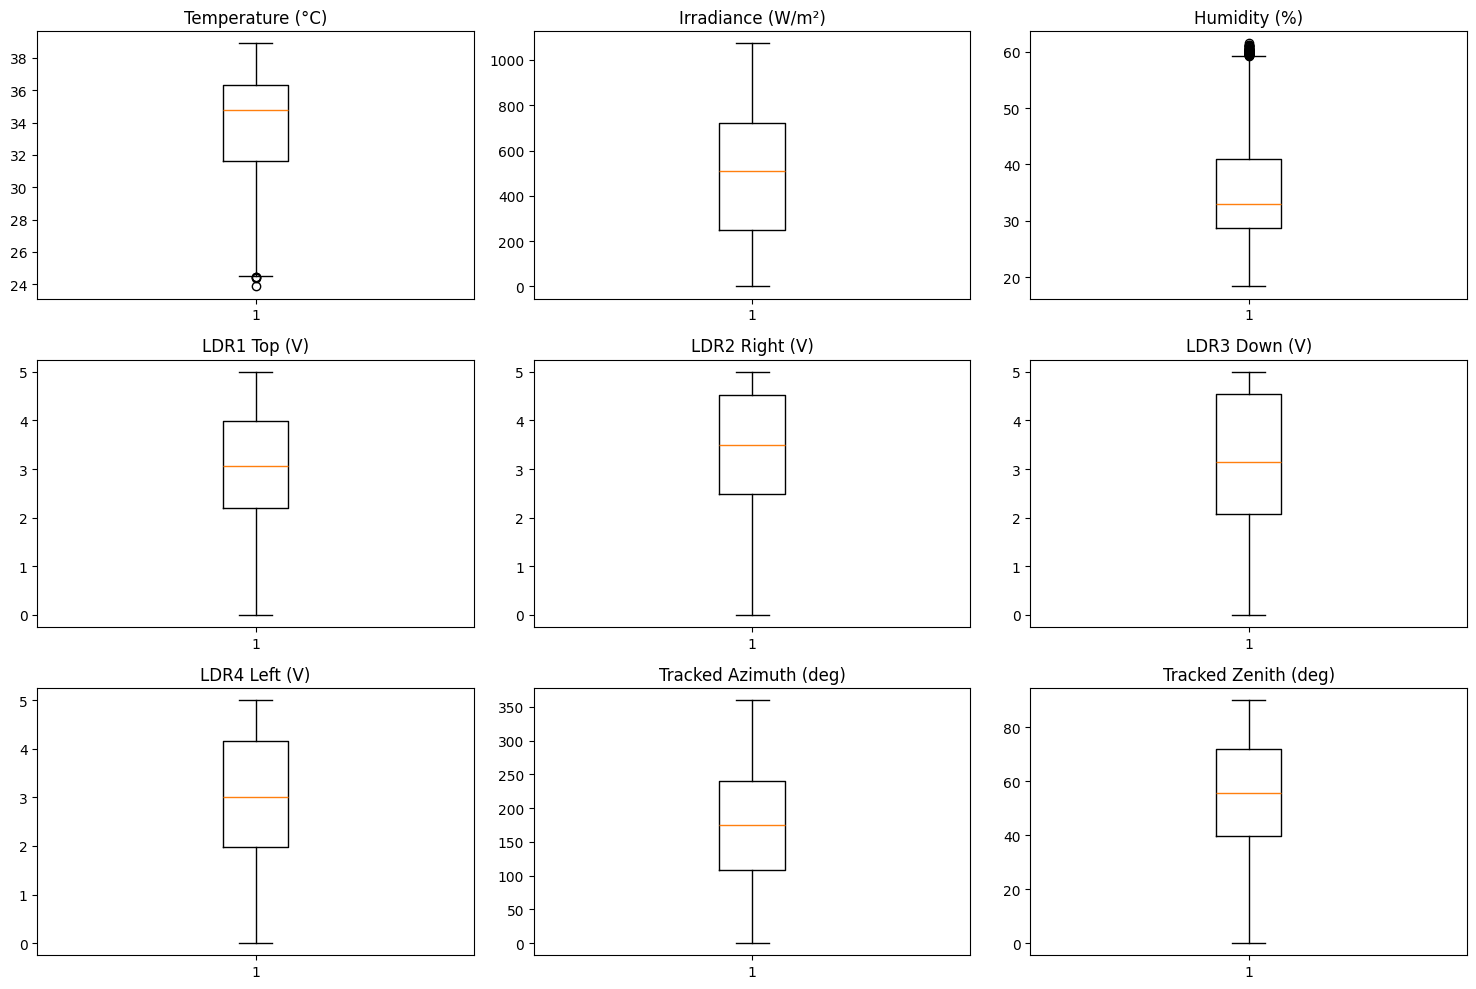

In [34]:

# İncelenecek sayısal sütunlar
sutunlar = ['Temperature (°C)', 'Irradiance (W/m²)', 'Humidity (%)',
            'LDR1 Top (V)', 'LDR2 Right (V)', 'LDR3 Down (V)', 'LDR4 Left (V)',
            'Tracked Azimuth (deg)', 'Tracked Zenith (deg)']

# Her sütun için ayrı kutu grafiği çiz
fig, eksenler = plt.subplots(3, 3, figsize=(15, 10))
for eksen, sutun in zip(eksenler.flat, sutunlar):
    eksen.boxplot(veri[sutun])
    eksen.set_title(sutun)
plt.tight_layout()
plt.show()

**Gözlemler:**
- Tüm ölçümler fiziksel olarak mümkün aralıklar içindedir; hatalı (imkânsız) değer bulunmamaktadır.
- Sıcaklıkta düşük yaklaşık 24 °C ve nemde yüksek yaklaşık %60 yönde az sayıda istatistiksel aykırı değer görülmektedir. Bu değerler kış ayları ve sabah saatlerine ait gerçek hava koşullarını yansıttığı için veride korunmuştur.
- LDR sensörleri güçlü ışıkta 5 V üst sınırına ulaşmaktadır (doygunluk). Bu bir hata değil, sensörün ölçüm sınırıdır.
- Kutu grafikleri değerlerin aralığını gösterir ancak zaman içindeki ani sıçramaları yakalayamaz. Bu nedenle açı sütunları ayrıca zaman serisi olarak incelenecektir.

### 5.1 Açı Ölçümlerinde Gürültü ve Ani Sıçramalar
Kutu grafikleri değer aralığını gösterir, ancak zaman içindeki ani değişimleri yakalayamaz. Açılar zaman serisi olduğundan, örnek bir gün için açıların zamana göre değişimi incelenir.

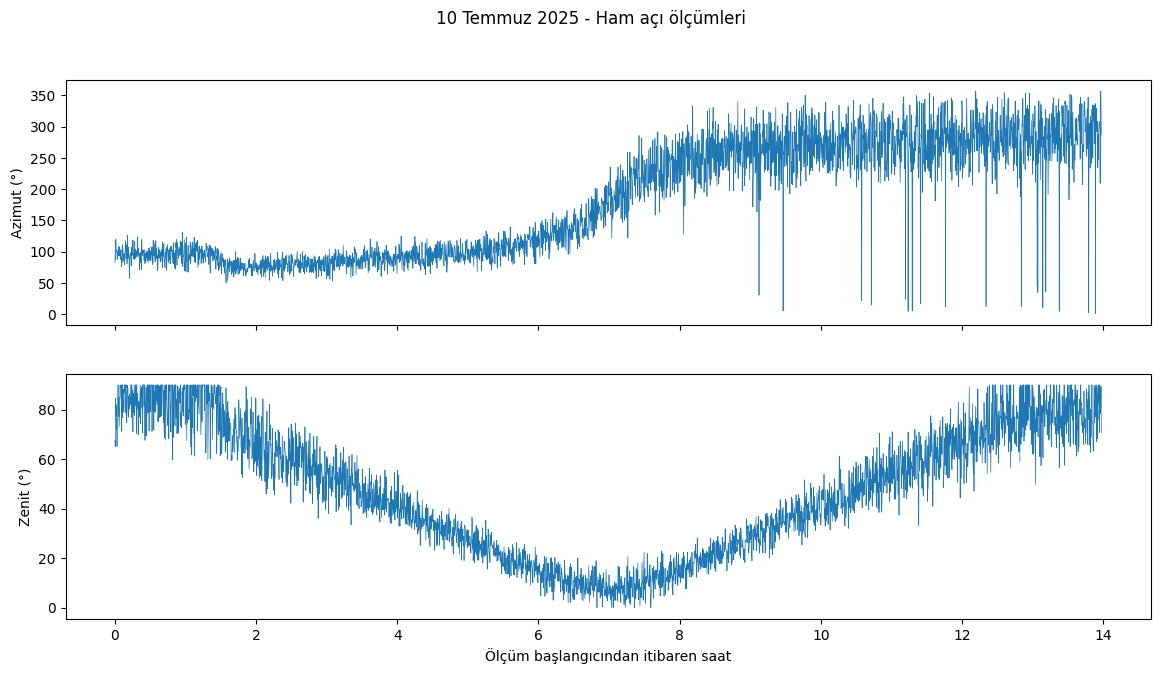

In [35]:
# Örnek bir günü seç
ornek = veri[veri['gun'] == '2025-07-10']

# Azimut ve zenit açılarını zamana göre çiz
fig, eksenler = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
eksenler[0].plot(ornek['Time (s)'] / 3600, ornek['Tracked Azimuth (deg)'], linewidth=0.5)
eksenler[0].set_ylabel('Azimut (°)')
eksenler[1].plot(ornek['Time (s)'] / 3600, ornek['Tracked Zenith (deg)'], linewidth=0.5)
eksenler[1].set_ylabel('Zenit (°)')
eksenler[1].set_xlabel('Ölçüm başlangıcından itibaren saat')
plt.suptitle('10 Temmuz 2025 - Ham açı ölçümleri')
plt.show()

Açı ölçümlerinde yüksek gürültü ve tekil hatalı değerler (ör. 261° → 0,5° → 259°) görülmektedir. Bu nedenle her gün için ayrı olarak 21 ölçümlük (yaklaşık 5 dakika) hareketli medyan uygulanmıştır. Medyan, tekil hatalı değerlerden etkilenmediği için ortalamaya tercih edilmiştir. Ham değerler korunmuş, yumuşatılmış değerler yeni sütunlara yazılmıştır.

In [36]:
# Her gün için ayrı ayrı 21 ölçümlük hareketli medyan uygula
for sutun, yeni_ad in [('Tracked Azimuth (deg)', 'azimut_duzgun'),
                       ('Tracked Zenith (deg)', 'zenit_duzgun')]:
    veri[yeni_ad] = veri.groupby('gun')[sutun].transform(
        lambda s: s.rolling(21, center=True, min_periods=1).median())

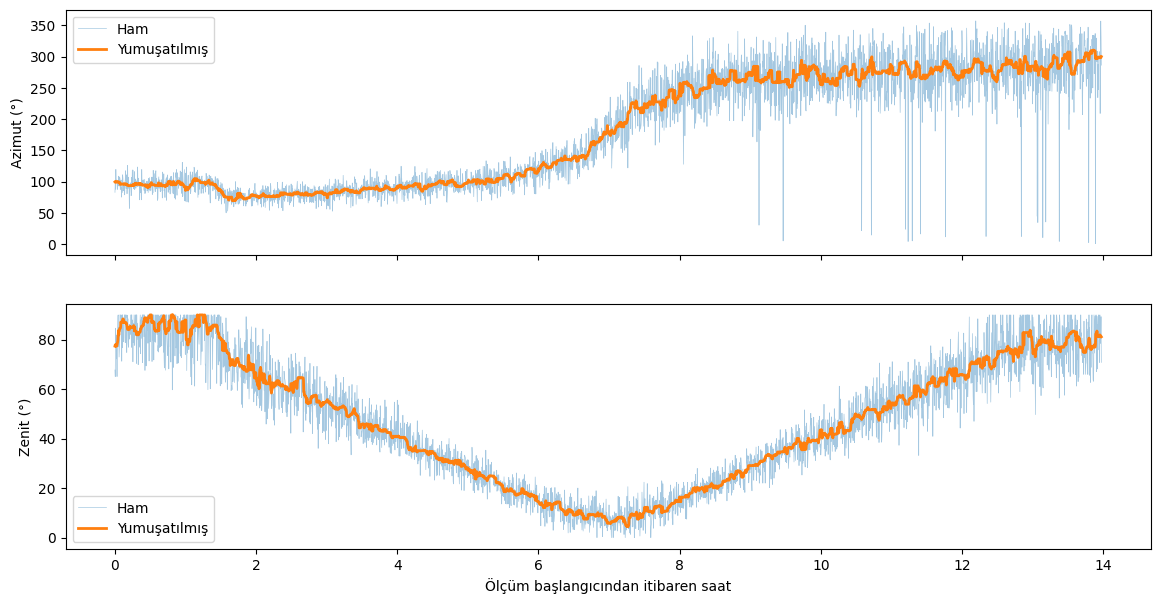

In [37]:
# Örnek günü tekrar seç (yeni sütunlarla)
ornek = veri[veri['gun'] == '2025-07-10']
saat = ornek['Time (s)'] / 3600

# Ham ve yumuşatılmış açıları üst üste çiz
fig, eksenler = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
eksenler[0].plot(saat, ornek['Tracked Azimuth (deg)'], linewidth=0.5, alpha=0.4, label='Ham')
eksenler[0].plot(saat, ornek['azimut_duzgun'], linewidth=2, label='Yumuşatılmış')
eksenler[0].set_ylabel('Azimut (°)'); eksenler[0].legend()
eksenler[1].plot(saat, ornek['Tracked Zenith (deg)'], linewidth=0.5, alpha=0.4, label='Ham')
eksenler[1].plot(saat, ornek['zenit_duzgun'], linewidth=2, label='Yumuşatılmış')
eksenler[1].set_ylabel('Zenit (°)'); eksenler[1].legend()
eksenler[1].set_xlabel('Ölçüm başlangıcından itibaren saat')
plt.show()

**Gözlemler:**
- Hareketli medyan, açı ölçümlerindeki gürültüyü ve tekil hatalı değerleri (0°'ye ani düşüşler) başarıyla gidermiştir.
- Yumuşatılmış zenit açısı beklenen V şeklini çizmektedir: sabah yaklaşık 85°, öğlen yaklaşık 7°, akşam yaklaşık 80°.
- Zenitin en düşük değeri ölçüm süresinin tam ortasında (14 saatlik günün 7. saatinde) görülmektedir. Bu, "Time Stamp" sütununun gerçek saati değil, gün doğumundan itibaren geçen süreyi gösterdiğini doğrulamaktadır.
- Azimut sabah doğu (\~90°), akşam batı (\~290°) yönündedir. Öğle saatlerinde hızlı değişim görülmesi, yaz aylarında güneşin tepe noktasına yakın geçmesinden kaynaklanan fiziksel bir durumdur.
- Öğleden sonra azimut gürültüsü artmaktadır; yumuşatılmış değerlerde de küçük dalgalanmalar kalmaktadır.

## 6. Özellik Mühendisliği
### 6.1 LDR Özellikleri
Ham LDR değerleri yerine, ışığın yönünü ve şiddetini doğrudan gösteren yeni özellikler türetilir. Sensör farkları toplam değere bölünerek ışık şiddetinden bağımsız hâle getirilir.

In [38]:

# Dört LDR sütunu
ldr = ['LDR1 Top (V)', 'LDR2 Right (V)', 'LDR3 Down (V)', 'LDR4 Left (V)']
toplam = veri[ldr].sum(axis=1)

# Genel ışık seviyesi: dört sensörün ortalaması
veri['ldr_ort'] = veri[ldr].mean(axis=1)

# Yatay hata: (sağ - sol) / toplam  -> pozitifse ışık sağdan geliyor
veri['yatay_hata'] = (veri['LDR2 Right (V)'] - veri['LDR4 Left (V)']) / toplam

# Dikey hata: (üst - alt) / toplam  -> pozitifse ışık yukarıdan geliyor
veri['dikey_hata'] = (veri['LDR1 Top (V)'] - veri['LDR3 Down (V)']) / toplam

# Yayılım: en büyük ve en küçük sensör arasındaki farkın ortalamaya oranı
veri['yayilim'] = (veri[ldr].max(axis=1) - veri[ldr].min(axis=1)) / veri['ldr_ort']

# Doygunluk: kaç sensör 5 V üst sınırına ulaşmış
veri['doygun_sayisi'] = (veri[ldr] >= 4.99).sum(axis=1)

# Tüm sensörler 0 iken (karanlık) bölme sonucu boş çıkar; bunları 0 yap
veri[['yatay_hata', 'dikey_hata', 'yayilim']] = veri[['yatay_hata', 'dikey_hata', 'yayilim']].fillna(0)

veri[['ldr_ort', 'yatay_hata', 'dikey_hata', 'yayilim', 'doygun_sayisi']].describe()

,ldr_ort,yatay_hata,dikey_hata,yayilim,doygun_sayisi
count,354027.000000,354027.000000,354027.000000,354027.000000,354027.000000
mean,3.135433,0.032852,-0.013385,0.564907,0.555418
std,1.157143,0.107635,0.117785,0.249972,0.787217
min,0.000000,-1.000000,-1.000000,0.000000,0.000000
25%,2.387518,-0.041526,-0.108955,0.436278,0.000000
50%,3.485403,0.050316,-0.016725,0.538556,0.000000
75%,4.067795,0.111260,0.083963,0.649503,1.000000
max,4.940117,1.000000,1.000000,4.000000,3.000000


**Gözlemler:**
- Yeni özelliklerde boş değer bulunmamaktadır.
- Yatay ve dikey hatanın ortalaması 0'a yakındır; panel çoğu zaman güneşe dönük ve sensörler dengededir.
- Hataların -1 ile +1 arasında değişmesi, ışığın tamamen tek taraftan geldiği anları (sabah ve akşam) göstermektedir.
- Yatay hatanın hafif pozitif olması, sağ sensörün genelde daha fazla ışık aldığını gösterir.

### 6.2 Zaman Özellikleri
Time Stamp gerçek saati değil, gün doğumundan itibaren geçen süreyi gösterdiği için zaman bilgisi yeniden düzenlenir. Günün ne kadarının geçtiği (gün oranı) ve yılın hangi günü olduğu (mevsim) yeni özellikler olarak eklenir. Yılın günü, döngüsel yapısını korumak için sinüs ve kosinüs ile ifade edilir.

In [39]:
# Gün doğumundan itibaren geçen süre (saat)
veri['saat'] = veri['Time (s)'] / 3600

# O günün toplam uzunluğu (saat): her günün en büyük süresi
veri['gun_uzunlugu'] = veri.groupby('gun')['saat'].transform('max')

# Günün ne kadarı geçti: 0 = gün doğumu, 0.5 = öğle, 1 = gün batımı
veri['gun_orani'] = veri['saat'] / veri['gun_uzunlugu']

# Yılın kaçıncı günü (sayfa adındaki tarihten)
yilin_gunu = pd.to_datetime(veri['gun']).dt.dayofyear

# Mevsim bilgisi: yılı bir çember gibi göstermek için sinüs ve kosinüs
veri['gun_sin'] = np.sin(2 * np.pi * yilin_gunu / 365)
veri['gun_cos'] = np.cos(2 * np.pi * yilin_gunu / 365)

veri[['saat', 'gun_uzunlugu', 'gun_orani', 'gun_sin', 'gun_cos']].describe()

,saat,gun_uzunlugu,gun_orani,gun_sin,gun_cos
count,354027.000000,354027.000000,354027.000000,354027.000000,354027.000000
mean,6.179179,12.358359,0.500000,-0.056894,-0.118378
std,3.663253,1.431835,0.288774,0.533319,0.835657
min,0.000000,10.241667,0.000000,-0.863142,-0.999963
25%,3.045833,10.845833,0.249908,-0.545240,-0.905193
50%,6.091667,13.016667,0.500000,-0.111659,-0.605056
75%,9.141667,13.700000,0.750092,0.432776,0.814046
max,14.054167,14.054167,1.000000,0.849817,0.999852


**Gözlemler:**
- Gün uzunluğu kışın yaklaşık 10,2 saat, yazın yaklaşık 14,1 saattir; bu değerler gerçek gün uzunluklarıyla uyumludur.
- Gün oranı 0 (gün doğumu) ile 1 (gün batımı) arasında değişmektedir; böylece mevsimden bağımsız olarak günün hangi bölümünde olunduğu ifade edilmiştir.

## 7. Işık Durumu Etiketleme
Sınıflandırma modeli için her ölçüme ışınım değerine göre bir etiket verilir: yetersiz (< 100 W/m²), dağınık (100–400 W/m²) ve yönlü (≥ 400 W/m²). Eşik değerler bu çalışmada belirlenen varsayımlardır.

Etiket ışınım sensöründen üretilir, ancak model girdisi olarak yalnızca LDR özellikleri kullanılır. Böylece veri sızıntısı önlenir ve model, maketimizde de bulunan LDR sensörlerine bakarak ışık durumunu tahmin etmeyi öğrenir.

In [40]:
isinim = veri['Irradiance (W/m²)']

# Işınıma göre etiket: <100 yetersiz, 100-400 dağınık, >=400 yönlü
veri['etiket'] = np.select(
    [isinim < 100, isinim < 400],      # koşullar sırayla kontrol edilir
    ['yetersiz', 'daginik'],           # koşullara karşılık gelen etiketler
    default='yonlu')                   # hiçbiri değilse

# Her etiketten kaç tane var?
print(veri['etiket'].value_counts())
print()
print((veri['etiket'].value_counts(normalize=True) * 100).round(1))

etiket
yonlu       217785
daginik      95662
yetersiz     40580
Name: count, dtype: int64

etiket
yonlu       61.5
daginik     27.0
yetersiz    11.5
Name: proportion, dtype: float64


**Sonuç:** Ölçümlerin %61,5'i yönlü, %27'si dağınık, %11,5'i yetersiz ışık olarak etiketlenmiştir. Veri seti çoğunlukla açık havada toplandığı için yönlü ışık baskındır. Sınıflar dengesiz olduğundan model değerlendirmesinde doğruluğun yanında F1 skoru da kullanılacaktır.

### 7.1 İşlenmiş Verinin Kaydedilmesi
Ön işleme, özellik mühendisliği ve etiketleme sonrası veri Drive'a kaydedilir. Böylece ekip arkadaşları tüm adımları baştan çalıştırmadan aynı veriyi kullanabilir. Ham veri değiştirilmeden korunur.

In [41]:
# İşlenmiş veri klasörü (yoksa oluştur)
islenmis_klasor = '/content/drive/MyDrive/gunes-takip-paneli/veri/islenmis'
os.makedirs(islenmis_klasor, exist_ok=True)

# İşlenmiş veriyi kaydet
veri.to_csv(f'{islenmis_klasor}/soltrack_islenmis.csv', index=False)
print(os.listdir(islenmis_klasor))

['soltrack_islenmis.csv']


## 8. Eğitim, Doğrulama ve Test Verisinin Ayrılması
Veri gün bazında %70 eğitim, %15 doğrulama ve %15 test olarak ayrılır. Ardışık ölçümler birbirine çok benzediği için satırlar rastgele bölünseydi aynı günün verisi hem eğitimde hem testte yer alır ve model başarısı olduğundan yüksek görünürdü (veri sızıntısı). Bu nedenle her günün tamamı yalnızca bir gruba atanmıştır.

In [42]:
from sklearn.model_selection import GroupShuffleSplit

# 1. bölme: günlerin %70'i eğitim, %30'u geri kalan
bolucu = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
egitim_idx, kalan_idx = next(bolucu.split(veri, groups=veri['gun']))
egitim = veri.iloc[egitim_idx]
kalan = veri.iloc[kalan_idx]

# 2. bölme: kalanın yarısı doğrulama, yarısı test
bolucu2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
dogrulama_idx, test_idx = next(bolucu2.split(kalan, groups=kalan['gun']))
dogrulama = kalan.iloc[dogrulama_idx]
test = kalan.iloc[test_idx]

# Kontrol: her grupta kaç gün ve kaç satır var
for ad, parca in [('Eğitim', egitim), ('Doğrulama', dogrulama), ('Test', test)]:
    print(f"{ad:10s}: {parca['gun'].nunique()} gün, {len(parca)} satır")

# Kontrol: eğitim ve test aynı günü içermemeli
print('Ortak gün var mı?', bool(set(egitim['gun']) & set(test['gun'])))

Eğitim    : 84 gün, 247222 satır
Doğrulama : 18 gün, 53082 satır
Test      : 19 gün, 53723 satır
Ortak gün var mı? False


**Sonuç:** Eğitim verisinde 84 gün (247.222 satır), doğrulama verisinde 18 gün (53.082 satır), test verisinde 19 gün (53.723 satır) bulunmaktadır. Eğitim ve test verisi arasında ortak gün yoktur.

## 9. Sınıflandırma Modeli: Işık Durumu
Model girdisi olarak yalnızca LDR özellikleri kullanılır. Basit bir model olan Lojistik Regresyon ile Random Forest karşılaştırılır. Sınıflar dengesiz olduğundan doğruluğun yanında her sınıfa eşit ağırlık veren F1 skoru (macro) da hesaplanır. Karşılaştırma doğrulama verisi üzerinde yapılır.

In [43]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

# Modele verilecek özellikler (sadece LDR'den türetilenler) ve hedef
ozellikler_sinif = ['ldr_ort', 'yatay_hata', 'dikey_hata', 'yayilim', 'doygun_sayisi']
X_egitim, y_egitim = egitim[ozellikler_sinif], egitim['etiket']
X_dog, y_dog = dogrulama[ozellikler_sinif], dogrulama['etiket']

# Karşılaştırılacak iki model
modeller = {
    'Lojistik Regresyon': LogisticRegression(max_iter=1000),
    'Random Forest': RandomForestClassifier(n_estimators=100, min_samples_leaf=5,
                                            n_jobs=-1, random_state=42)
}

# Her modeli eğit ve doğrulama verisinde değerlendir
sonuclar = []
for ad, model in modeller.items():
    model.fit(X_egitim, y_egitim)           # eğit
    tahmin = model.predict(X_dog)           # doğrulama verisinde tahmin et
    sonuclar.append({'Model': ad,
                     'Doğruluk': round(accuracy_score(y_dog, tahmin), 3),
                     'F1 (macro)': round(f1_score(y_dog, tahmin, average='macro'), 3)})

pd.DataFrame(sonuclar)

,Model,Doğruluk,F1 (macro)
0,Lojistik Regresyon,0.942,0.922
1,Random Forest,0.940,0.919


**Sonuç:** Lojistik Regresyon (%94,2 doğruluk, 0,922 F1) ve Random Forest (%94,0 doğruluk, 0,919 F1) neredeyse aynı başarıyı göstermiştir. Daha karmaşık model ek bir başarı sağlamadığı için, daha basit, hızlı ve açıklanabilir olan **Lojistik Regresyon** seçilmiştir. Basit bir modelin bu kadar başarılı olması, türetilen LDR özelliklerinin ışık durumunu iyi temsil ettiğini göstermektedir.

### 9.1 Seçilen Modelin Test Verisinde Değerlendirilmesi
Seçilen Lojistik Regresyon modeli, model seçiminde kullanılmayan test verisi üzerinde değerlendirilir. Karışıklık matrisi ile modelin hangi sınıfları birbirine karıştırdığı incelenir.

Test doğruluğu: 0.937
Test F1 (macro): 0.919

              precision    recall  f1-score   support

     daginik       0.89      0.89      0.89     15329
    yetersiz       0.91      0.89      0.90      6383
       yonlu       0.97      0.97      0.97     32011

    accuracy                           0.94     53723
   macro avg       0.92      0.92      0.92     53723
weighted avg       0.94      0.94      0.94     53723



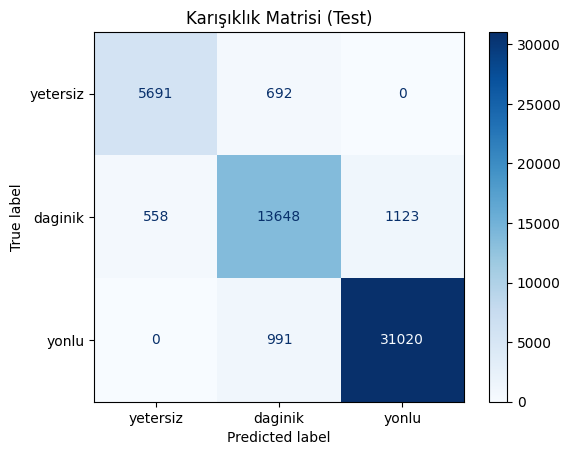

In [44]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Seçilen model
siniflandirici = modeller['Lojistik Regresyon']

# Test verisinde tahmin
X_test, y_test = test[ozellikler_sinif], test['etiket']
tahmin_test = siniflandirici.predict(X_test)

print('Test doğruluğu:', round(accuracy_score(y_test, tahmin_test), 3))
print('Test F1 (macro):', round(f1_score(y_test, tahmin_test, average='macro'), 3))
print()

# Her sınıf için ayrıntılı rapor
print(classification_report(y_test, tahmin_test))

# Karışıklık matrisi
siralama = ['yetersiz', 'daginik', 'yonlu']
ConfusionMatrixDisplay.from_predictions(y_test, tahmin_test, labels=siralama, cmap='Blues')
plt.title('Karışıklık Matrisi (Test)')
plt.show()

**Sonuç:** Model test verisinde %93,7 doğruluk ve 0,919 F1 skoru elde etmiştir. Bu değerin doğrulama sonucuna yakın olması, modelin ezber yapmadığını ve görmediği günlerde de başarılı olduğunu gösterir.

Karışıklık matrisine göre model yetersiz ve yönlü ışığı hiçbir zaman birbirine karıştırmamıştır; hatalar yalnızca komşu sınıflar arasında, eşik değerlere yakın ölçümlerde oluşmaktadır. En zor sınıf, iki sınıfın arasında kalan dağınık ışıktır (F1: 0,89).

## 10. Panel Açısı Modeli: Model Seçimi
Bulutlu havada LDR'ler ışığın yönünü gösteremediği için panelin açısı zamana bakarak tahmin edilir. Girdi olarak zaman özellikleri, çıktı olarak yumuşatılmış azimut ve zenit açıları kullanılır. Basit bir model olan Doğrusal Regresyon ile Random Forest doğrulama verisinde karşılaştırılır. Başarı MAE (ortalama kaç derece hata) ve R² ile ölçülür.

In [45]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

ozellikler_reg = ['saat', 'gun_orani', 'gun_uzunlugu', 'gun_sin', 'gun_cos']   # girdi: zaman özellikleri
hedefler = ['azimut_duzgun', 'zenit_duzgun']                                   # çıktı: panel açıları

modeller_reg = {
    'Doğrusal Regresyon': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=50, min_samples_leaf=200, n_jobs=-1, random_state=42)
}

sonuclar = []
for ad, model in modeller_reg.items():
    model.fit(egitim[ozellikler_reg], egitim[hedefler])            # eğit
    tahmin_dog = model.predict(dogrulama[ozellikler_reg])           # doğrulamada tahmin et
    for i, hedef in enumerate(hedefler):
        sonuclar.append({'Model': ad, 'Açı': hedef,
                         'MAE (°)': round(mean_absolute_error(dogrulama[hedef], tahmin_dog[:, i]), 2),
                         'R²': round(r2_score(dogrulama[hedef], tahmin_dog[:, i]), 3)})

pd.DataFrame(sonuclar)

,Model,Açı,MAE (°),R²
0,Doğrusal Regresyon,azimut_duzgun,17.08,0.905
1,Doğrusal Regresyon,zenit_duzgun,17.38,0.130
2,Random Forest,azimut_duzgun,5.24,0.990
3,Random Forest,zenit_duzgun,1.74,0.989


**Sonuç:** Doğrusal Regresyon azimutta yaklaşık 17°, zenitte yaklaşık 17° hata yaptı; zenitte R² yalnızca 0,13. Bunun nedeni zenitin gün içinde V şeklinde değişmesidir: düz bir çizgi bu şekli öğrenemez. Random Forest ise azimutta yaklaşık 5°, zenitte yaklaşık 2° hata yaptı ve iki açıda da R² 0,99'a ulaştı. Bu nedenle panel açısı modeli olarak **Random Forest** seçilmiştir.

## 11. Panel Açısı Modeli: Ayar ve Test
İlk denemede Random Forest modeli yaklaşık 400 MB yer kaplıyordu; GitHub'a ve backend'e taşımak için çok büyüktü. Her yaprakta en az 200 örnek olacak şekilde ayarladık (`min_samples_leaf=200`). Böylece model gürültülü küçük dalgalanmaları ezberlemedi; hem küçüldü hem başarısı arttı. Seçilen model, hiç görmediği test günlerinde denendi.

In [46]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Ayarlanmış model: 50 ağaç, her yaprakta en az 200 örnek (küçük ve ezber yapmayan model)
regresor = RandomForestRegressor(n_estimators=50, min_samples_leaf=200, n_jobs=-1, random_state=42)
regresor.fit(egitim[ozellikler_reg], egitim[hedefler])      # eğitim verisiyle öğren

tahmin = regresor.predict(test[ozellikler_reg])             # test günlerinde tahmin et

for i, hedef in enumerate(hedefler):                        # her açı için sonuç
    print(hedef, '→ MAE:', round(mean_absolute_error(test[hedef], tahmin[:, i]), 2), 'derece',
          '| R²:', round(r2_score(test[hedef], tahmin[:, i]), 3))

azimut_duzgun → MAE: 5.28 derece | R²: 0.988
zenit_duzgun → MAE: 2.01 derece | R²: 0.973


**Gözlem:** Model test günlerinde azimutu ortalama yaklaşık 5,3°, zeniti yaklaşık 2° hatayla tahmin etti. R² değerleri 1'e çok yakın, yani model güneşin gün içindeki hareketini neredeyse tamamen öğrenmiş. Test sonucu doğrulamaya yakın; model ezber yapmamış.

## 12. Gerçek ve Tahmin Edilen Açılar
Bir kış ve bir yaz test gününde modelin tahmin ettiği açıyı gerçek açıyla karşılaştırdık.

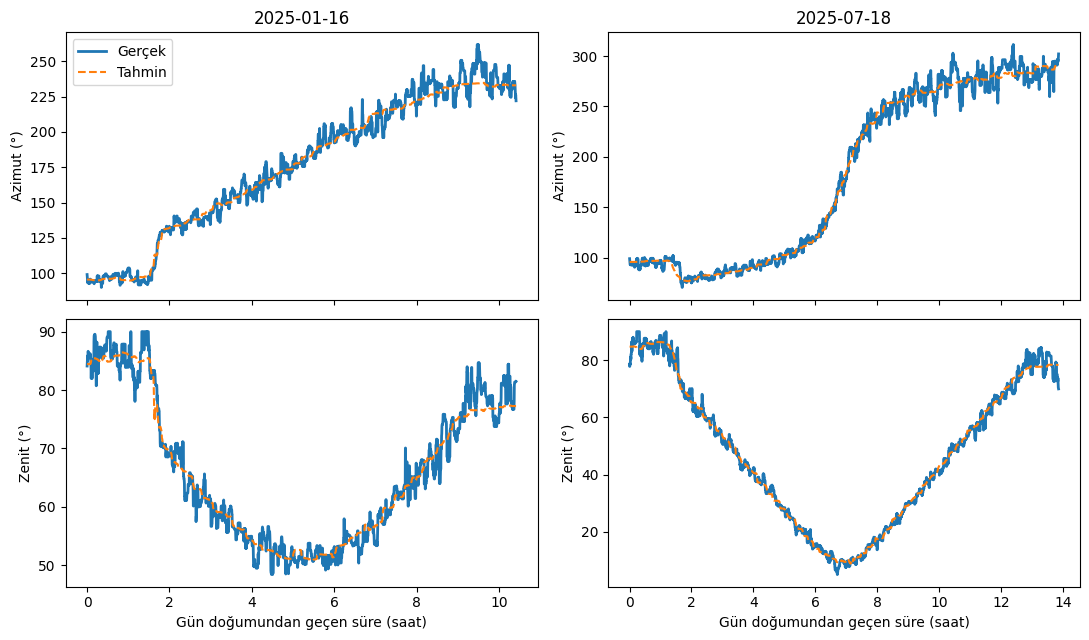

In [47]:
import matplotlib.pyplot as plt

test = test.copy()
test['azimut_tahmin'] = tahmin[:, 0]           # tahminleri test tablosuna ekle
test['zenit_tahmin'] = tahmin[:, 1]

fig, ax = plt.subplots(2, 2, figsize=(11, 6.5), sharex='col')
for j, gun in enumerate(['2025-01-16', '2025-07-18']):          # bir kış, bir yaz günü
    d = test[test['gun'] == gun]
    for i, (gercek, tah, ad) in enumerate([('azimut_duzgun', 'azimut_tahmin', 'Azimut (°)'),
                                            ('zenit_duzgun', 'zenit_tahmin', 'Zenit (°)')]):
        ax[i, j].plot(d['saat'], d[gercek], label='Gerçek', lw=2)
        ax[i, j].plot(d['saat'], d[tah], label='Tahmin', ls='--')
        ax[i, j].set_ylabel(ad)
    ax[0, j].set_title(gun)
    ax[1, j].set_xlabel('Gün doğumundan geçen süre (saat)')
ax[0, 0].legend()
plt.tight_layout()
plt.show()

**Gözlem:** Tahmin çizgisi gerçek açıyı çok yakından takip ediyor. Zenitte V şekli (sabah yüksek, öğlen en düşük, akşam yine yüksek) iki mevsimde de doğru yakalanmış. Kışın öğle zeniti yaklaşık 50°, yazın yaklaşık 10°; yani model mevsime göre güneşin ne kadar yükseldiğini öğrenmiş. Gerçek çizgideki küçük dalgalanmaları model takip etmiyor; bunlar ölçüm gürültüsü olduğu için bu istenen bir durum.

## 13. Modelleri Kaydetme
Backend'in kullanabilmesi için sınıflandırma modelini `classifier.pkl`, panel açısı modelini `regressor.pkl` olarak Drive'a kaydettik.

In [48]:
import joblib, os

model_klasor = '/content/drive/MyDrive/gunes-takip-paneli/modeller'
os.makedirs(model_klasor, exist_ok=True)                                  # klasör yoksa oluştur

joblib.dump(siniflandirici, f'{model_klasor}/classifier.pkl', compress=3)   # ışık durumu modeli
joblib.dump(regresor, f'{model_klasor}/regressor.pkl', compress=3)          # panel açısı modeli
print(os.listdir(model_klasor))

['classifier.pkl', 'regressor.pkl']
